In [3]:
# read the generated file (selected_models.csv) dont forget O in the output
# calculate features
# filter them ( 4 features)
# normalize them
# find weight with bwm

In [4]:
import numpy as np
import pandas as pd
from statsmodels.tsa.seasonal import STL
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy import stats
from scipy.signal import periodogram
from scipy.stats import boxcox
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

input_csv = "training_data.csv"

Calculate features and create the correlation matrix to extracte significatve features

In [5]:
# Box Cox
def apply_boxcox(y):
    shift = 0
    if np.any(y <= 0):
        shift = abs(np.min(y)) + 1
    y_shifted = y + shift
    y_transformed, _ = boxcox(y_shifted)
    return y_transformed

In [6]:
# decomposition
def get_decomposition(y, period):
    if period is not None and period > 1:
        stl    = STL(y, period=period, robust=True)
        result = stl.fit()
        T = result.trend
        S = result.seasonal
        R = result.resid
    else:
        t = np.arange(len(y))
        T = lowess(y, t, frac=0.3, return_sorted=False)
        S = np.zeros(len(y))
        R = y - T
    return T, S, R

In [7]:
# trend and seasonality strength
def strength_trend_seasonality(y_bc, period):
    T, S, R = get_decomposition(y_bc, period)

    var_R        = np.var(R, ddof=1)
    var_T_plus_R = np.var(T + R, ddof=1)
    var_S_plus_R = np.var(S + R, ddof=1)

    trend_str    = max(0.0, 1 - var_R / var_T_plus_R) if var_T_plus_R != 0 else 0.0
    seasonal_str = max(0.0, 1 - var_R / var_S_plus_R) if var_S_plus_R != 0 else 0.0

    return trend_str, seasonal_str

In [8]:
# curvature
def linearity_curvature(y_bc, period):
    y_scaled = (y_bc - np.mean(y_bc)) / np.std(y_bc, ddof=1)

    T_comp, _, _ = get_decomposition(y_scaled, period)

    t     = np.arange(1, len(T_comp) + 1, dtype=float)
    t_std = (t - np.mean(t)) / np.std(t, ddof=1)

    X    = np.column_stack([np.ones(len(t)), t_std, t_std**2])
    Q, _ = np.linalg.qr(X)
    coeffs, _, _, _ = np.linalg.lstsq(Q, T_comp, rcond=None)

    return float(coeffs[1]), float(coeffs[2])

In [9]:
# spikiness
def spikiness(y_bc, period):
    _, _, R  = get_decomposition(y_bc, period)
    n        = len(R)
    loo_vars = np.array([np.var(np.delete(R, i), ddof=1) for i in range(n)])
    return float(np.var(loo_vars, ddof=1))

In [10]:
# lumpiness
def stability_lumpiness(y_bc, window_size=None):
    n = len(y_bc)
    if window_size is None:
        window_size = max(4, n // 5)

    n_tiles = n // window_size
    if n_tiles < 2:
        return 0.0, 0.0

    tiles      = y_bc[:n_tiles * window_size].reshape(n_tiles, window_size)
    tile_means = np.mean(tiles, axis=1)
    tile_vars  = np.var(tiles,  axis=1, ddof=1)

    return float(np.var(tile_means, ddof=1)), float(np.var(tile_vars, ddof=1))

In [11]:
# spectral entropy
def spectral_entropy(y_bc):
    y_centered = y_bc - np.mean(y_bc)
    _, psd     = periodogram(y_centered, scaling='density')
    psd        = psd[psd > 0]
    psd_norm   = psd / np.sum(psd)
    ent        = -np.sum(psd_norm * np.log(psd_norm))
    return float(ent / np.log(len(psd_norm)))

In [12]:
# hurst exponent
def hurst_exponent(y_bc):
    n = len(y_bc)

    def rs_range(x):
        dev = np.cumsum(x - np.mean(x))
        R   = np.max(dev) - np.min(dev)
        S   = np.std(x, ddof=1)
        return R / S if S != 0 else np.nan

    min_w        = max(4, n // 10)
    window_sizes = np.unique(
        np.logspace(np.log10(min_w), np.log10(n), num=10, dtype=int)
    )

    rs_vals, valid_ws = [], []
    for w in window_sizes:
        n_wins = n // w
        if n_wins < 1:
            continue
        rs_w = np.nanmean([rs_range(y_bc[i*w:(i+1)*w]) for i in range(n_wins)])
        if not np.isnan(rs_w):
            rs_vals.append(rs_w)
            valid_ws.append(w)

    if len(valid_ws) < 2:
        return 0.5

    H, _, _, _, _ = stats.linregress(np.log(valid_ws), np.log(rs_vals))
    return float(np.clip(H, 0.01, 0.99))

In [13]:
# non linearity 
def nonlinearity(y_bc, lag=1):
    p = max(1, min(lag, len(y_bc) // 5))
    Y = y_bc[p:]
    n = len(Y)

    X_lag    = np.column_stack([y_bc[p-i-1:len(y_bc)-i-1] for i in range(p)])
    X_linear = np.column_stack([np.ones(n), X_lag])

    beta_lin, _, _, _ = np.linalg.lstsq(X_linear, Y, rcond=None)
    residuals         = Y - X_linear @ beta_lin
    SSR_lin           = np.sum(residuals**2)

    nl_terms = [X_lag[:, i] * X_lag[:, j]
                for i in range(p) for j in range(i, p)]
    if not nl_terms:
        return 0.0

    X_aux = np.column_stack([X_linear, np.column_stack(nl_terms)])

    try:
        beta_aux, _, _, _ = np.linalg.lstsq(X_aux, Y, rcond=None)
        SSR_aux = np.sum((Y - X_aux @ beta_aux)**2)
        return float(n * (1 - SSR_aux / SSR_lin)) if SSR_lin != 0 else 0.0
    except Exception:
        return 0.0

In [14]:
# extraction per serie
def extract_features(y, period=4):
    if len(y) < period * 2 + 2:
        return None

    try:
        y_bc = apply_boxcox(y)

        trend, seasonality = strength_trend_seasonality(y_bc, period)
        lin, curv          = linearity_curvature(y_bc, period)
        spik               = spikiness(y_bc, period)
        stab, lump         = stability_lumpiness(y_bc)
        ent                = spectral_entropy(y_bc)
        H                  = hurst_exponent(y_bc)
        nl                 = nonlinearity(y_bc)

        feats = {
            "trend":        trend,
            "seasonality":  seasonality,
            "linearity":    lin,
            "curvature":    curv,
            "spikiness":    spik,
            "stability":    stab,
            "lumpiness":    lump,
            "entropy":      ent,
            "hurst":        H,
            "nonlinearity": nl,
        }

        if any(not np.isfinite(v) for v in feats.values()):
            return None

        return feats

    except Exception as e:
        print(f"    Error: {e}")
        return None


In [15]:
# process all series
def process_all_series(input_csv, period=4):
    df = pd.read_csv(input_csv, index_col=0).T

    results, skipped = [], []

    for i, (series_name, row) in enumerate(df.iterrows()):
        y = row.dropna().values.astype(float)
        feats = extract_features(y, period=period)

        if feats is not None:
            results.append({"series": series_name, **feats})
        else:
            skipped.append(series_name)

    out_df = pd.DataFrame(results)
    return out_df
process_all_series(input_csv, period=4)

,series,trend,seasonality,linearity,curvature,spikiness,stability,lumpiness,entropy,hurst,nonlinearity
0,series_0001,0.815495,0.133051,4.551442,-0.322212,1.556650e+08,7.530160e+05,2.151843e+10,0.703009,0.923809,3.468926e-01
1,series_0002,0.902757,0.000000,5.395620,0.033698,2.832999e-06,1.880308e-01,1.480698e-04,0.482532,0.990000,4.138114e-01
2,series_0003,0.822618,0.000000,5.351639,0.477440,9.464748e-39,4.122353e-18,2.501707e-36,0.655909,0.981484,-1.710337e-07
3,series_0004,0.657904,0.221730,-0.175600,2.066458,6.452673e-31,2.005245e-14,1.440384e-28,0.707568,0.990000,1.638190e+00
4,series_0005,0.991214,0.023094,7.622844,-0.550848,3.937930e-17,1.418901e-05,3.401734e-13,0.331742,0.990000,3.180898e-01
...,...,...,...,...,...,...,...,...,...,...,...
2969,series_2995,0.997603,0.077423,7.259497,-0.139957,6.933536e-35,8.718351e-14,9.560484e-30,0.476662,0.990000,7.218457e-01
2970,series_2997,0.996161,0.144711,6.513415,0.415749,2.309392e+29,3.074158e+18,1.234816e+34,0.476488,0.990000,7.571211e-01
2971,series_2998,0.971619,0.000000,7.721121,0.543770,2.016216e-05,4.520113e+00,5.934268e-03,0.384698,0.990000,1.642237e-02
2972,series_2999,0.554020,0.067037,4.631835,-0.144192,3.980109e-10,4.571306e-04,2.249651e-07,0.789446,0.922793,2.321211e-01


In [16]:
def remove_correlated_features(df, threshold=0.3):
    df = df.drop(columns=["series"], errors="ignore")

    corr_matrix = df.corr(method="pearson").abs()

    upper = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    to_drop = [col for col in upper.columns if any(upper[col] >= threshold)]

    df_reduced = df.drop(columns=to_drop)

    print(f"\nFeatures dropped (|r| >= {threshold}): {to_drop}")
    print(f"Features kept: {list(df_reduced.columns)}")


Features dropped (|r| >= 0.3): ['linearity', 'stability', 'lumpiness', 'entropy', 'hurst', 'nonlinearity']
Features kept: ['trend', 'seasonality', 'curvature', 'spikiness']


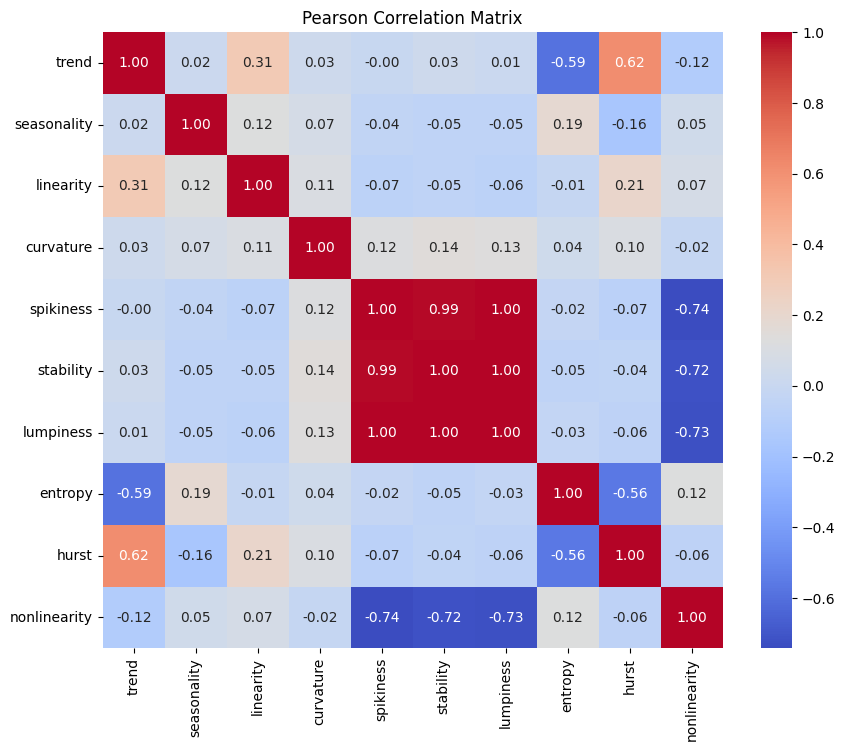

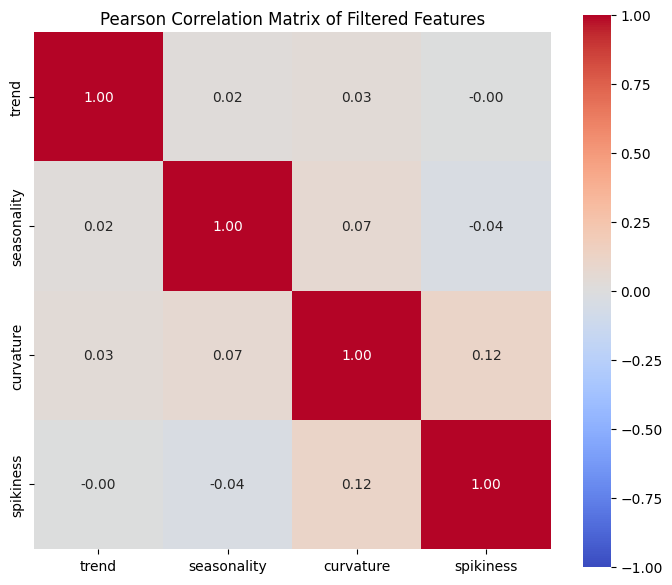

In [17]:
df = process_all_series(input_csv, period=4).drop(columns=["series"])
df = df.replace([np.inf, -np.inf], np.nan).dropna()
for c in df.columns:
    df[c] = df[c].clip(df[c].quantile(0.05), df[c].quantile(0.95))
for c in ["spikiness", "stability", "lumpiness", "nonlinearity"]:
    m = df[c].min()
    df[c] = np.log1p(df[c] + (abs(m) + 1e-6 if m <= 0 else 0))
remove_correlated_features(df, threshold=0.3)

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(method="pearson"), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Pearson Correlation Matrix")

# correlation matrix of non correlated features
corr_abs = df.corr(method="pearson").abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
kept = [col for col in upper.columns if not any(upper[col] >= 0.3)]
plt.figure(figsize=(7, 6))
sns.heatmap(df[kept].corr(method="pearson"), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Pearson Correlation Matrix of Filtered Features")
plt.tight_layout()
plt.show()


The output gives spikniess, curvature, trend and seasonnality as non correlated features defining the series, let's normalize them ([0,1])

In [22]:
print("Maximum value of curvature:", df["curvature"].abs().max())

Maximum value of curvature: 6.698709392927174


In [19]:
result_df = process_all_series(input_csv, period=4)

df = result_df.copy()

def normalized_curvature(y_bc, period, beta2_max_abs=6.698709392927174):
    y_scaled = (y_bc - np.mean(y_bc)) / np.std(y_bc, ddof=1)
    T_comp, _, _ = get_decomposition(y_scaled, period)

    t = np.arange(1, len(T_comp) + 1, dtype=float)
    t_std = (t - np.mean(t)) / np.std(t, ddof=1)

    X = np.column_stack([np.ones(len(t)), t_std, t_std**2])
    Q, _ = np.linalg.qr(X)
    coeffs, _, _, _ = np.linalg.lstsq(Q, T_comp, rcond=None)

    # Eq. 3.3: |beta2| / max|beta2|
    # Length-independent alternative: divide by np.sqrt(len(T_comp) - 1) instead
    return float(abs(coeffs[2]) / beta2_max_abs)

def normalized_spikiness(y_bc, period):
    _, _, R = get_decomposition(y_bc, period)
    n = len(R)

    def relative_disp(r):
        median_abs = np.median(np.abs(r))
        return 0.0 if median_abs == 0 else np.mean(np.abs(r - np.mean(r))) / median_abs

    loo_disp = np.array([relative_disp(np.delete(R, i)) for i in range(n)])
    d_bar = np.mean(loo_disp)
    return 0.0 if d_bar == 0 else float(np.mean(np.abs(loo_disp - d_bar) / d_bar))

raw = pd.read_csv(input_csv, index_col=0).T
curv, spik = {}, {}
for name in df["series"]:
    y = raw.loc[name].dropna().values.astype(float)
    y_bc = apply_boxcox(y)
    curv[name] = normalized_curvature(y_bc, period=4)
    spik[name] = normalized_spikiness(y_bc, period=4)
df["curvature_norm"] = df["series"].map(curv).round(6)
df["spikiness_norm"] = df["series"].map(spik).round(6)

normalized_df = df[["series", "trend", "seasonality", "curvature_norm", "spikiness_norm"]]
print(normalized_df.to_string(index=False))


     series    trend  seasonality  curvature_norm  spikiness_norm
series_0001 0.815495     0.133051        0.048101        0.104066
series_0002 0.902757     0.000000        0.005030        0.042991
series_0003 0.822618     0.000000        0.071273        0.037503
series_0004 0.657904     0.221730        0.308486        0.079008
series_0005 0.991214     0.023094        0.082232        0.013441
series_0006 0.617819     0.036210        0.302619        0.035142
series_0007 0.707154     0.186347        0.211090        0.027022
series_0008 0.698835     0.000000        0.183778        0.050273
series_0009 0.813866     0.000000        0.070963        0.018367
series_0010 0.936624     0.117947        0.066003        0.085473
series_0011 0.933827     0.084619        0.054207        0.064495
series_0012 0.994207     0.000000        0.026108        0.023599
series_0013 0.908799     0.798810        0.667281        0.014996
series_0014 0.994151     0.150180        0.007687        0.037892
series_001

BWM Weight determination

In [ ]:
cols = ["trend", "seasonality", "curvature_norm", "spikiness_norm"]
names = {"trend": "w_trend", "seasonality": "w_seasonality",
         "curvature_norm": "w_curvature", "spikiness_norm": "w_spikiness"}

weighted_df = normalized_df[["series"]].copy()
row_total = normalized_df[cols].sum(axis=1)

for c in cols:
    weighted_df[names[c]] = (normalized_df[c] / row_total).where(row_total != 0, 0.0).round(6)

selected = pd.read_csv("O_selected_models.csv")
keep = set(selected["sample"].astype(str).str.strip())

weighted_df = weighted_df[weighted_df["series"].astype(str).str.strip().isin(keep)]
weighted_df = weighted_df.reset_index(drop=True)

weighted_df.to_csv("O_BWM_weights.csv", index=False)